# 11d — Figure 2 MC for the Notebook 11c PySR exponential

Notebook 11c selected seed 20261093 from the existing 100 PySR seeds by an exploratory subgroup-balanced rule. This notebook propagates the uncertainty of that **fixed exponential structure** through $D_M/r_d$ and $w(z)$. Every execution gets a new directory under `results/11d_fig2_selected_exponential_mc/`. Original Notebook 11/11b outputs remain unchanged.

## Fixed input and Monte Carlo protocol

The raw seed-selected expression is

$$D_M(z)/r_d=29.321836856709833z/1.2843234947453503^z\equiv 29.321836856709833z\exp(-0.25023211648356675z).$$

Use the Notebook 08 Figure 2 DESI+Pantheon+ data and **full prepared covariance**. For each of two centres—(i) the raw PySR expression and (ii) the observed data vector—generate Gaussian mock catalogues and draw one common $r_d$ per catalogue. Refit the two coefficients within the fixed family $a z\exp(bz)$ for every mock, as in Notebook 11b; never rerun PySR or change structure. The nominal raw coefficients are not silently replaced by a GLS refit for the model-centred mocks.

Paper Eq. (5) transforms each draw into $w(z)$:

$$w(z)=-1-\frac{2(1+z)D''+3\gamma(1+z)^3(D')^3}{3[D'-\gamma(1+z)^3(D')^3]},\qquad \gamma=\Omega_m(100r_d/c)^2.$$

Save *all finite* draws and, separately, the *pole-free* subset. The 1/2/3-sigma quantiles are pointwise and conditional on the selected functional family. The pole-free filter changes the sampling distribution; it is not an innocuous cleanup. This experiment is a post-audit follow-up, not a preregistered independent selection.

In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
from IPython.display import display, Image
PROJECT_ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
                    if (p / 'results/08_fig23_data_preparation/fig2_pantheon.npz').is_file())
sys.path.insert(0, str(PROJECT_ROOT))
from src.fig2_selected_exponential_mc import run_notebook11d
OUTPUT_ROOT = PROJECT_ROOT / 'results/11d_fig2_selected_exponential_mc'
print('Project:', PROJECT_ROOT)

Project: /Users/kemingliu/Desktop/Dark Energy


## Run or inspect

The notebook opens in inspection mode so it does not accidentally make another 20,000-draw experiment. Set `RUN_ANALYSIS=True` to run it again. The command-line runner switches that value automatically.

In [2]:
RUN_ANALYSIS = False
N_DRAWS = 20000
BATCH_SIZE = 500
MC_SEED = 20261016
if RUN_ANALYSIS:
    EXPERIMENT_DIR, SUMMARY = run_notebook11d(PROJECT_ROOT, n_draws=N_DRAWS,
                                            batch_size=BATCH_SIZE, base_seed=MC_SEED)
else:
    completed = sorted(p for p in OUTPUT_ROOT.glob('fig2_exp_mc_*')
                       if (p / 'experiment.json').is_file() and
                       json.loads((p / 'experiment.json').read_text()).get('status') == 'complete')
    if not completed:
        raise FileNotFoundError('No completed 11d run; set RUN_ANALYSIS=True.')
    EXPERIMENT_DIR = completed[-1]
    SUMMARY = json.loads((EXPERIMENT_DIR / 'summary.json').read_text())
print('Experiment:', EXPERIMENT_DIR)
print('Selected seed:', SUMMARY['selected_seed'], 'raw loss:', SUMMARY['raw_combined_loss'])
display(pd.DataFrame(SUMMARY['centers']))

Experiment: /Users/kemingliu/Desktop/Dark Energy/results/11d_fig2_selected_exponential_mc/fig2_exp_mc_20261016T045826099551Z_1de02bcb
Selected seed: 20261093 raw loss: 0.8836502786355833


,center,n_draws,n_finite,n_pole_crossing,n_pole_free,n_nonincreasing
0,raw_selected_expression,20000,20000,1478,18522,0
1,observed_data,20000,20000,1466,18534,0


## Inspect distance and $w(z)$ intervals

Each figure shows all finite realizations on the top row and the separately conditioned pole-free subset below. The paper curve is a reference only. The model-centred and data-centred bootstraps should not be conflated.

raw_selected_expression


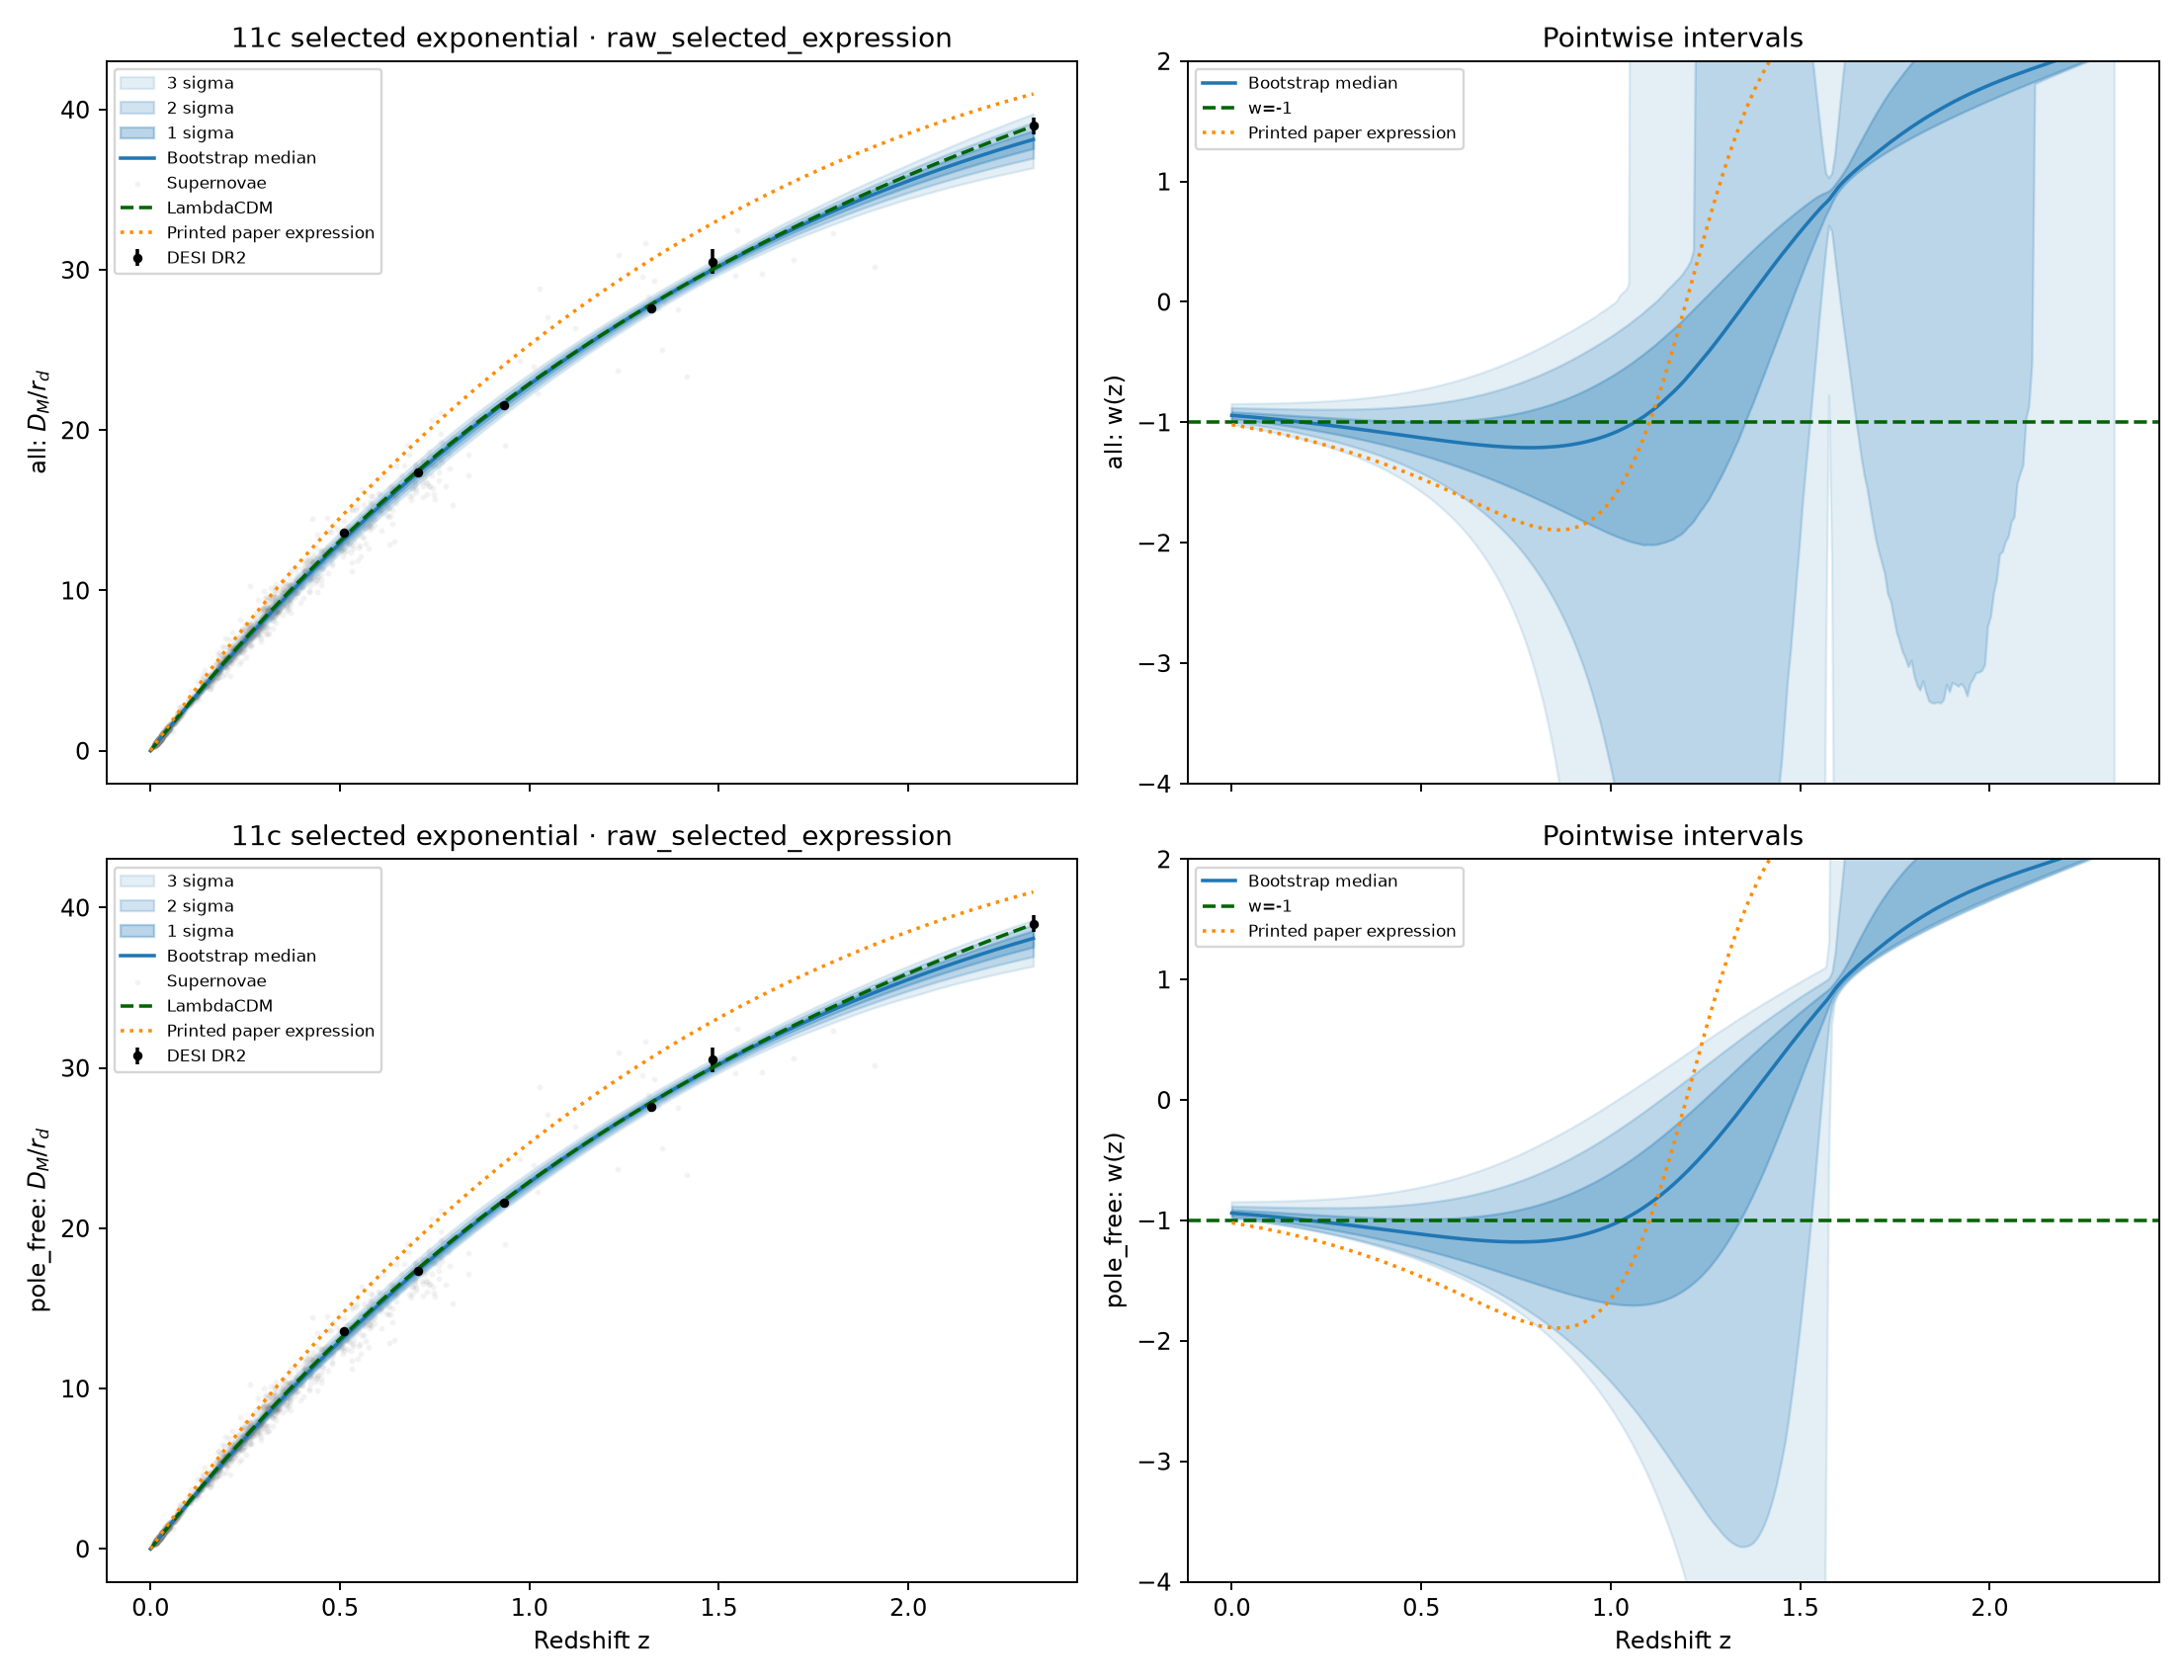

observed_data


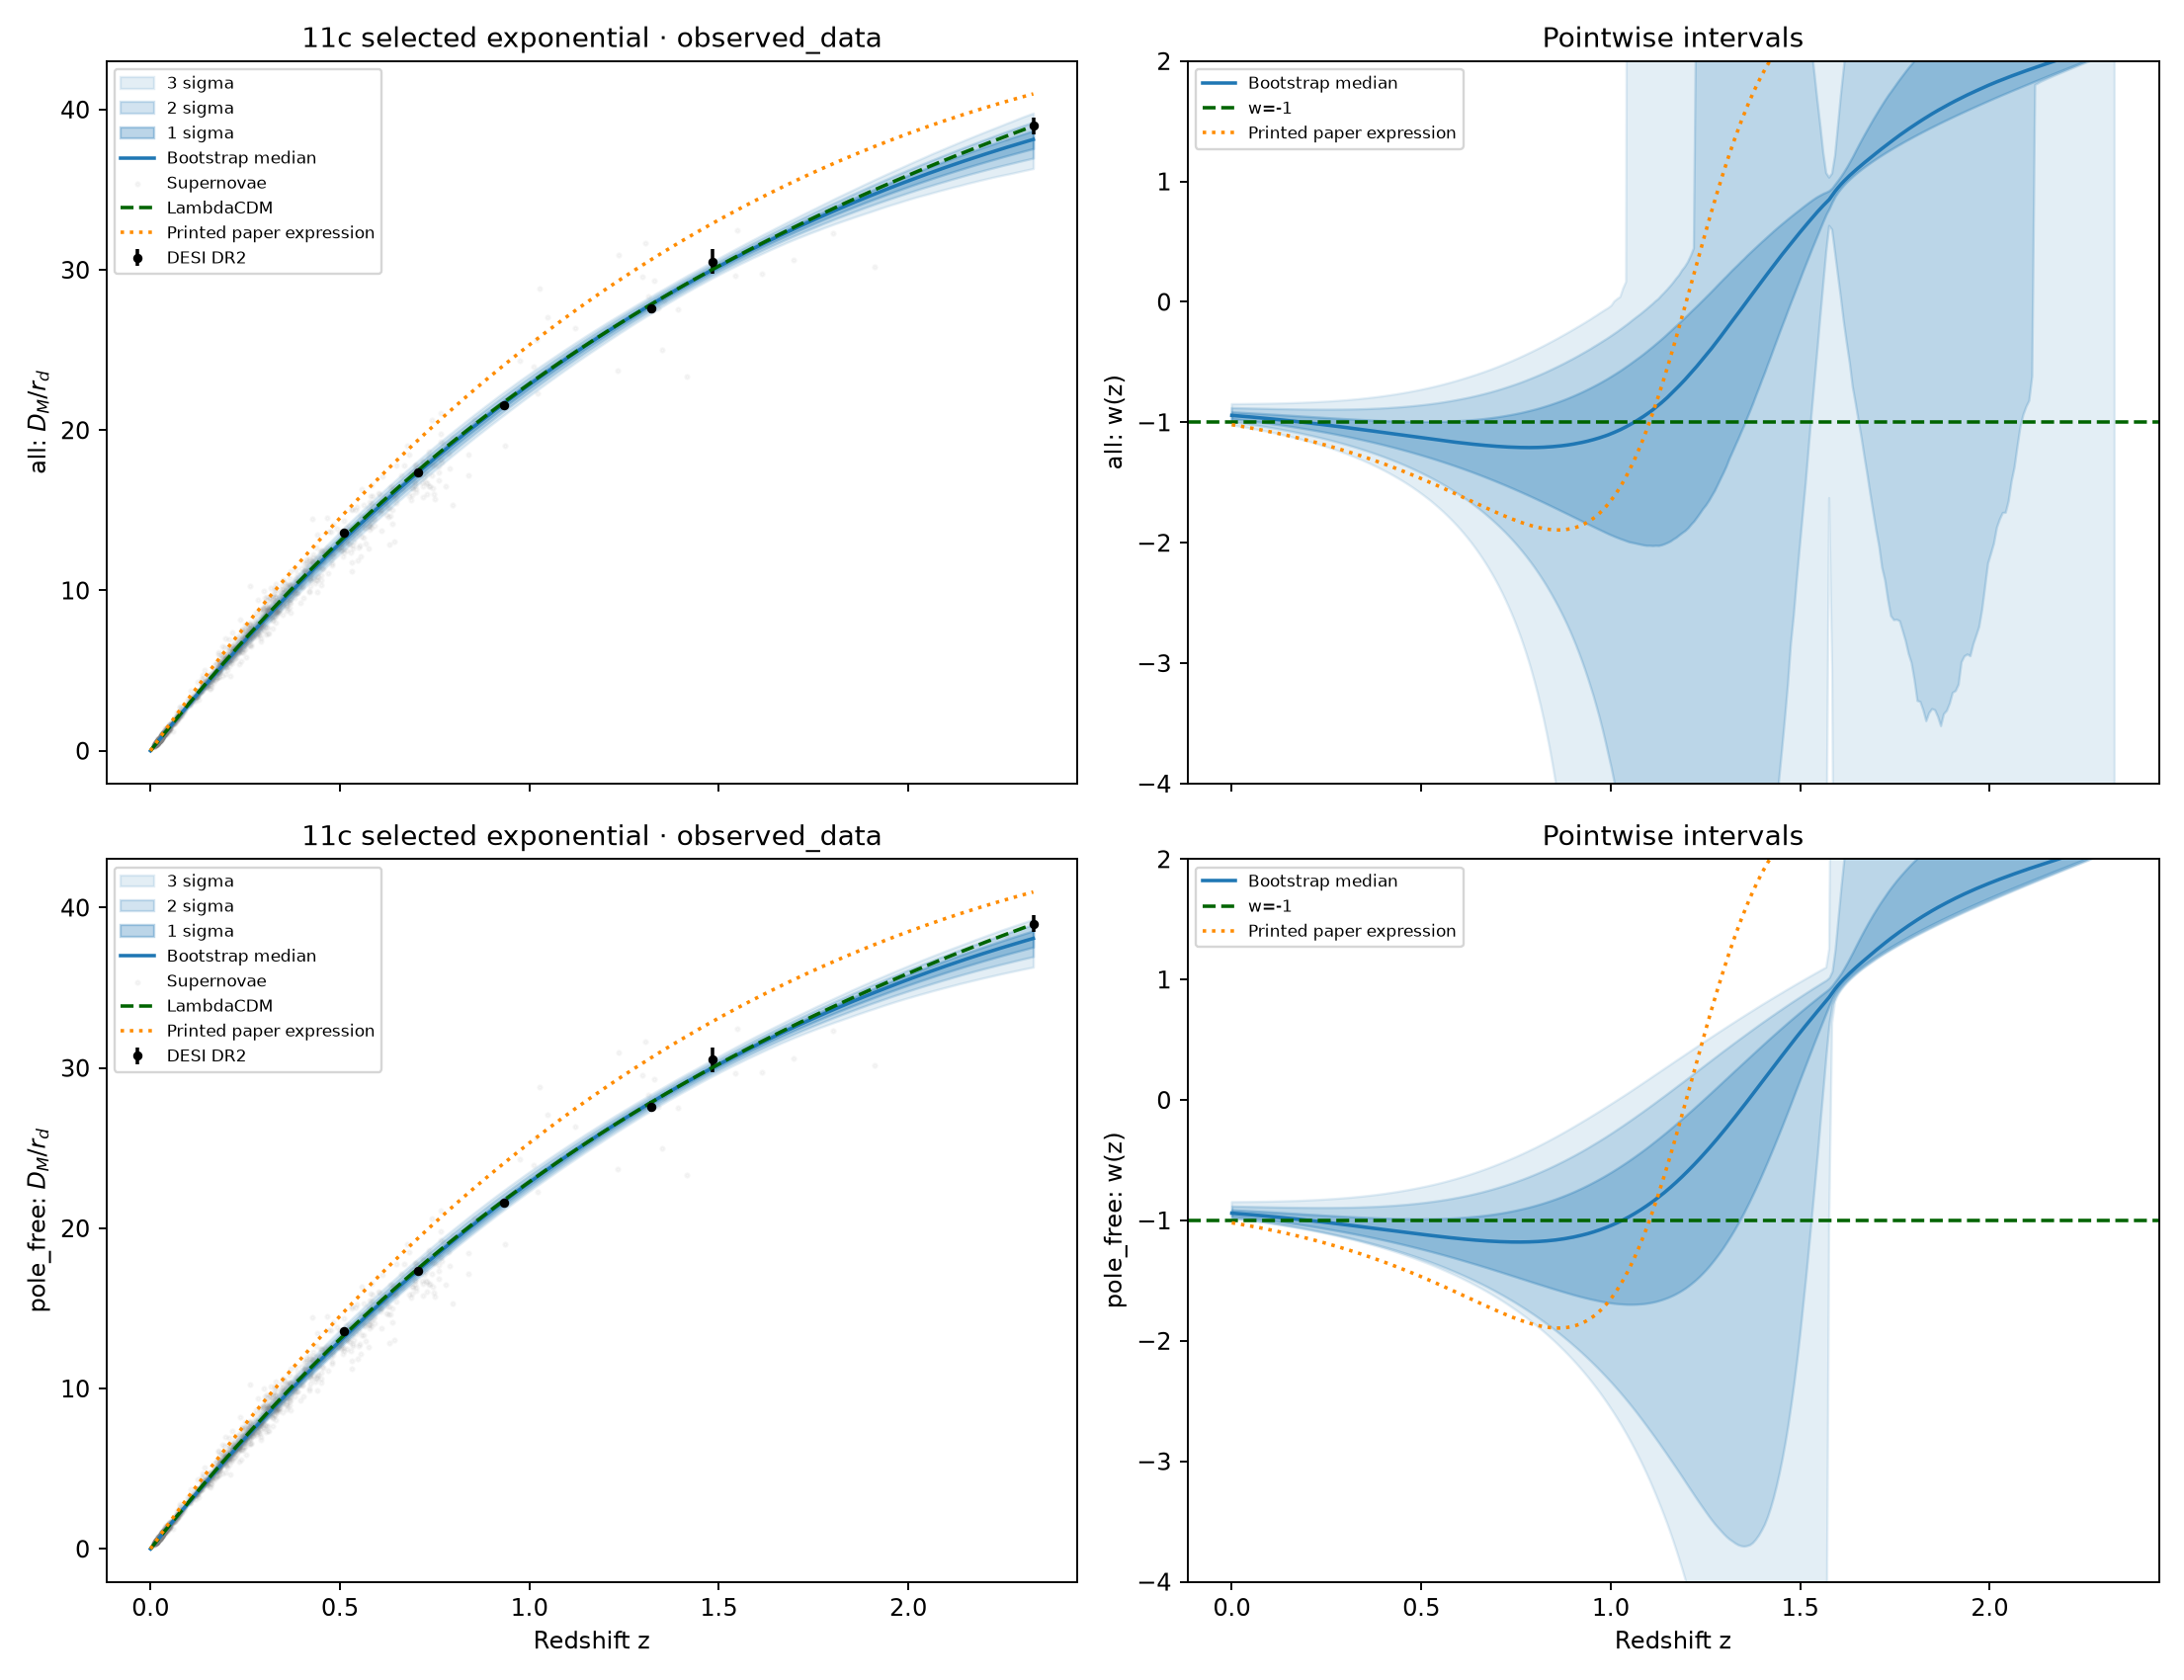

In [3]:
for center in ('raw_selected_expression', 'observed_data'):
    print(center)
    display(Image(filename=str(EXPERIMENT_DIR / f'{center}_reconstruction.png')))

## Check selected redshifts and provenance

The table below indicates only whether $w=-1$ lies within the **pointwise** 3-sigma interval at a few grid positions. It is not a global exclusion claim; neighboring grid points are strongly dependent. The full band table, individual fitted mock coefficients, and source hashes are saved alongside the notebook analysis.

In [4]:
checkpoints = pd.read_csv(EXPERIMENT_DIR / 'w_checkpoints.csv')
display(checkpoints)
print((EXPERIMENT_DIR / 'analysis.md').read_text())

,center,selection,z,raw_central_w,median_w,pointwise_3sigma_low,pointwise_3sigma_high,minus_one_inside_pointwise_3sigma
0,raw_selected_expression,all,0.000000,-0.942188,-0.942192,-1.022596,-0.848529,True
1,raw_selected_expression,all,0.100967,-0.970349,-0.970364,-1.079377,-0.844721,True
2,raw_selected_expression,all,0.201933,-1.004303,-1.004312,-1.155318,-0.835103,True
3,raw_selected_expression,all,0.497067,-1.126675,-1.126890,-1.570787,-0.732214,True
4,raw_selected_expression,all,1.001900,-1.094478,-1.095655,-12.160163,-0.031534,True
5,raw_selected_expression,all,1.498967,0.533598,0.578160,-62.483471,46.064709,True
6,raw_selected_expression,all,2.330000,2.142420,2.165210,-45.636022,38.541783,True
7,raw_selected_expression,pole_free,0.000000,-0.942188,-0.939529,-0.982685,-0.848240,False
8,raw_selected_expression,pole_free,0.100967,-0.970349,-0.966758,-1.025207,-0.844299,True
9,raw_selected_expression,pole_free,0.201933,-1.004303,-0.999397,-1.079796,-0.834351,True


# Notebook 11d — MC for the Figure 2 seed-20261093 exponential

The raw PySR expression is the source of the fixed model structure and the model-centered mock-catalogue mean. Each Gaussian mock catalogue is refitted within the exponential family using the full prepared covariance.

Raw expression: `29.321836856709833*z/1.2843234947453503**z`

Equivalent form: `D_M/r_d = 29.321836856710 z exp(-0.250232116484 z)`

Raw-expression combined loss: 0.883650; GLS refitted-family loss: 0.883650.

| Mock centre | Draws | Finite | Pole crossing | Pole-free |
| --- | ---: | ---: | ---: | ---: |
| raw_selected_expression | 20000 | 20000 | 1478 | 18522 |
| observed_data | 20000 | 20000 | 1466 | 18534 |

The raw central equation gives w(0) = -0.942 and w(2.33) = 2.142. For the raw-expression-centred MC, the **unfiltered** pointwise 3-sigma band includes w = -1 at all listed checkpoints (z = 0, 0.101, 0.202, 0.497, 1.002, 1.499, 2.330); it misses at only one isolated grid point near z = 1.577. That on